# B12 — Exercice : régression polynomiale, biais-variance et courbes d'apprentissage

**Énoncé (carnet CS229, B12, étape 7)** : régression polynomiale de degré 1 à 15 sur 30 points bruités. Tracer l'erreur train/test en fonction du degré, puis les courbes d'apprentissage.

**Règles** : NumPy et Matplotlib uniquement, pas de scikit-learn.

**Mode d'emploi**
- Exécute les cellules **dans l'ordre** (`Shift + Entrée`).
- Complète chaque cellule marquée `# TODO`. Tant qu'elle n'est pas complétée, elle lève `NotImplementedError` : c'est normal.
- Réponds aux questions dans les cellules **« Tes réponses »** (double-clic pour éditer).
- Des points de contrôle te permettent de vérifier ton code au fil de l'eau.

| Partie | Contenu | Durée |
|---|---|---|
| 1 | Briques de base : features, ajustement, MSE | 15 min |
| 2 | Erreur train/test en fonction du degré | 30 min |
| 3 | Courbes d'apprentissage | 35 min |
| 4 | Bonus : conditionnement et valeurs propres | 15 min |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Partie 0 — Les données (fourni, ne pas modifier)

- Vraie relation, inconnue du modèle : $y = \sin(2\pi x)$, avec $x \in [0, 1]$.
- Bruit gaussien d'écart-type $\sigma = 0{,}25$. L'erreur minimale atteignable est donc $\sigma^2 = 0{,}0625$.
- 30 points d'entraînement, et 2 000 points de test pour estimer précisément l'erreur de test.

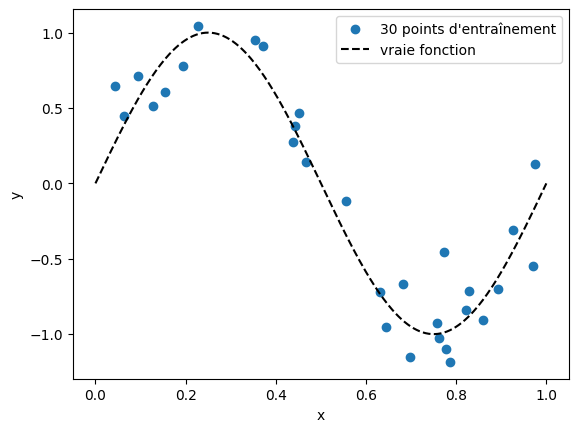

In [44]:
SIGMA = 0.25            # écart-type du bruit -> erreur minimale atteignable = SIGMA**2


def f_vraie(x):
    """La 'vraie' relation, inconnue du modèle."""
    return np.sin(2 * np.pi * x)


def generer(n, rng):
    """Tire n exemples : x uniforme sur [0, 1], y = f_vraie(x) + bruit gaussien."""
    x = rng.uniform(0, 1, n)
    y = f_vraie(x) + rng.normal(0, SIGMA, n)
    return x, y


rng = np.random.default_rng(42)
x_train, y_train = generer(30, rng)     # 30 points d'entraînement
x_test, y_test = generer(2000, rng)     # gros jeu de test

def generer(n, rng):
    x= rng.uniform(0,1,n)
    y=f_vraie(x)+rng.normal(0,SIGMA,n)
    return x,y

plt.scatter(x_train, y_train, label="30 points d'entraînement")
grille = np.linspace(0, 1, 300)
plt.plot(grille, f_vraie(grille), "k--", label="vraie fonction")
plt.legend(); plt.xlabel("x"); plt.ylabel("y")
plt.show()

## Partie 1 — Les briques de base

### 1.a `features_poly`

Construit la matrice de design $X$ de taille $(n, \text{deg}+1)$, de colonnes $[1, z, z^2, \dots, z^{\text{deg}}]$ avec $z = 2x - 1$.

Le changement de variable ramène $x$ de $[0, 1]$ vers $[-1, 1]$. Tu verras pourquoi en partie 4 (lien direct avec le cours sur les valeurs propres).

*Indice : `np.vander(z, deg + 1, increasing=True)`, ou une boucle sur les puissances.*

In [39]:
def features_poly(x, deg):
    z =2*x-1
    X =np.vander(z, deg+1, increasing=True)
    return X

    raise NotImplementedError

### 1.b `ajuster`

Renvoie le $\theta$ des moindres carrés. N'utilise **pas** `np.linalg.inv(X.T @ X)` : utilise `np.linalg.lstsq(X, y, rcond=None)[0]`.

In [45]:
def ajuster(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

### 1.c `mse`

Erreur quadratique moyenne : moyenne de $(X\theta - y)^2$.

In [46]:
def mse(X, y, theta):
    return np.mean((X @ theta - y) ** 2)

### ✅ Point de contrôle 1

Exécute la cellule suivante. Elle doit afficher `Partie 1 OK`.

In [47]:
X_verif = features_poly(np.array([0.0, 0.5, 1.0]), 2)
print(X_verif)
assert X_verif.shape == (3, 3), f"forme attendue (3, 3), obtenue {X_verif.shape}"
assert np.allclose(X_verif, [[1, -1, 1], [1, 0, 0], [1, 1, 1]]), "colonnes attendues : 1, z, z**2 avec z = 2x - 1"

X_lin = features_poly(np.array([0.0, 1.0]), 1)          # droite passant par 2 points
theta_lin = ajuster(X_lin, np.array([1.0, 3.0]))
print(theta_lin)
assert np.allclose(theta_lin, [2, 1]), "la droite passant par (z=-1, 1) et (z=1, 3) est y = 2 + z"
assert np.isclose(mse(X_lin, np.array([1.0, 3.0]), theta_lin), 0), "MSE nulle attendue pour un ajustement exact"
print("Partie 1 OK")

[[ 1. -1.  1.]
 [ 1.  0.  0.]
 [ 1.  1.  1.]]
[2. 1.]
Partie 1 OK


**Question** : pourquoi `lstsq` est-il préférable à l'inversion explicite de $X^\top X$ ? *(Pense au conditionnement.)*

**Tes réponses :**

- 

## Partie 2 — Erreur train / test en fonction du degré

### 2.a Calcul des erreurs

Pour chaque degré $d$ de 1 à 15 :
- construire `X_train` et `X_test` avec `features_poly` ;
- ajuster $\theta$ sur le **train uniquement** ;
- calculer la MSE sur le train et sur le test, et les ajouter aux listes ;
- afficher une ligne : degré, MSE train, MSE test.

In [52]:
degres = list(range(1, 16))
err_train, err_test = [], []

for d in degres:
    X_train = features_poly(x_train, d)     # matrice de design du train pour ce degré
    X_test = features_poly(x_test, d)            # pareil pour le test

    theta = ajuster(X_train, y_train)                             # ajuster sur le TRAIN uniquement

    err_train.append(mse(X_train, y_train, theta))                   # MSE sur le train
    err_test.append(mse(X_test, y_test, theta))                    # MSE sur le test

    print(f"degré {d:2d} | MSE train {err_train[-1]:.4f} | MSE test {err_test[-1]:.4f}")

degré  1 | MSE train 0.1931 | MSE test 0.2617
degré  2 | MSE train 0.1888 | MSE test 0.2645
degré  3 | MSE train 0.0461 | MSE test 0.0682
degré  4 | MSE train 0.0444 | MSE test 0.0722
degré  5 | MSE train 0.0329 | MSE test 0.0786
degré  6 | MSE train 0.0311 | MSE test 0.0919
degré  7 | MSE train 0.0311 | MSE test 0.0895
degré  8 | MSE train 0.0310 | MSE test 0.0837
degré  9 | MSE train 0.0304 | MSE test 0.0742
degré 10 | MSE train 0.0303 | MSE test 0.0741
degré 11 | MSE train 0.0298 | MSE test 0.0941
degré 12 | MSE train 0.0252 | MSE test 1.1160
degré 13 | MSE train 0.0244 | MSE test 0.4890
degré 14 | MSE train 0.0218 | MSE test 3.6992
degré 15 | MSE train 0.0212 | MSE test 1.3326


### ✅ Point de contrôle 2

Avec les mêmes graines, tu dois obtenir **exactement** :

| Degré | MSE train | MSE test |
|---|---|---|
| 1 | 0,193 | 0,262 |
| 3 | 0,046 | 0,068 |
| 14 | 0,022 | ≈ 3,7 |

### 2.b Tracé des erreurs

Trace `err_train` et `err_test` en fonction du degré :
- échelle log sur l'axe y (`plt.yscale("log")`), sinon les grands degrés écrasent tout ;
- une ligne horizontale à `SIGMA**2` (le bruit irréductible) ;
- titre, légende, noms d'axes.

Text(0, 0.5, 'Valeur erreur MSE')

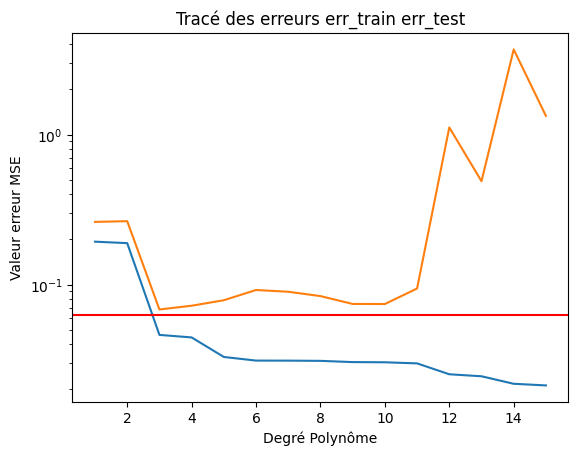

In [58]:
plt.plot(np.linspace(1,15,15), err_train)
plt.plot(np.linspace(1,15,15), err_test)
plt.axhline(SIGMA**2, color='red')
plt.yscale("log")
plt.title("Tracé des erreurs err_train err_test")
plt.xlabel("Degré Polynôme")
plt.ylabel("Valeur erreur MSE")

### 2.c Visualiser les polynômes

Sur une nouvelle figure, trace :
- les 30 points d'entraînement ;
- la vraie fonction ;
- les polynômes ajustés de degré 1, 3 et 14, évalués sur une grille fine de $x$ entre 0 et 1.

Limite l'axe y à $[-2, 2]$.

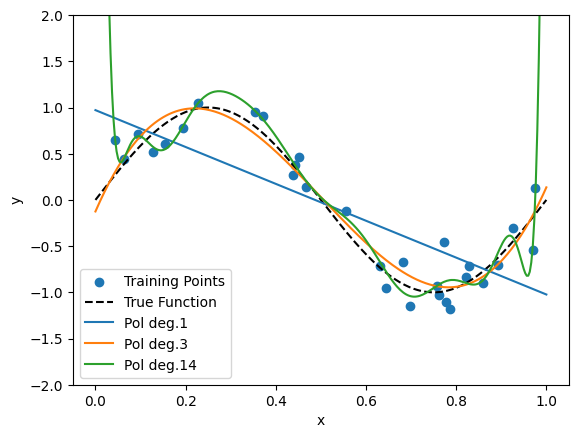

In [76]:
plt.scatter(x_train, y_train, label ="Training Points")
grille = np.linspace(0,1,300)
plt.plot(grille,f_vraie(grille),"k--", label="True Function")

for d in (1, 3, 14):
    theta = ajuster(features_poly(x_train, d),y_train)
    y_pred = features_poly(grille, d)@theta
    plt.plot(grille, y_pred, label=f"Pol deg.{d}")

plt.ylim(-2, 2)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

### Questions — Partie 2

- **Q1.** Pourquoi l'erreur train diminue-t-elle toujours quand le degré augmente ?
- **Q2.** Quel degré minimise l'erreur de test ? Pourquoi pas le degré 15 ?
- **Q3.** Quels degrés sont en sous-apprentissage, lesquels en sur-apprentissage ? Justifie avec les deux erreurs (biais / variance).
- **Q4.** L'erreur de test peut-elle descendre sous $\sigma^2$ ? Pourquoi ?

**Tes réponses :**

- Q1 :
- Q2 :
- Q3 :
- Q4 : 

## Partie 3 — Courbes d'apprentissage

### 3.a `courbe_apprentissage`

Pour chaque taille $m$ dans `tailles` :
- répéter `n_rep` fois : tirer un **nouveau** jeu de $m$ points avec `generer(m, rng)`, ajuster le polynôme de degré `deg`, calculer la MSE train (sur ces $m$ points) et la MSE test (sur `x_test`, `y_test`) ;
- garder la **moyenne** des MSE train et la **médiane** des MSE test (la médiane résiste aux quelques tirages catastrophiques).

Renvoie deux tableaux, erreurs train et erreurs test, avec une valeur par taille.

In [71]:
def courbe_apprentissage(deg, tailles, n_rep, rng):
    moy_train, med_test = [], []
    X_te=features_poly(x_test, deg)

    for m in tailles:
        e_tr, e_te = [], []
        for elem in range(n_rep):
            x, y = generer(m, rng)
            X = features_poly(x, deg)
            theta = ajuster(X, y)
            e_tr.append(mse(X,y,theta))
            e_te.append(mse(X_te, y_test, theta))

        moy_train.append(np.mean(e_tr))
        med_test.append(np.median(e_te))

    return(np.array(moy_train), np.array(med_test))
    raise NotImplementedError

### 3.b Tracés

Calcule et trace les courbes d'apprentissage pour les degrés **1, 4 et 12** :
- trois graphes côte à côte (`plt.subplots(1, 3, figsize=(15, 4))`), erreurs en échelle log ;
- une ligne horizontale à `SIGMA**2`.

*Le calcul prend quelques secondes.*

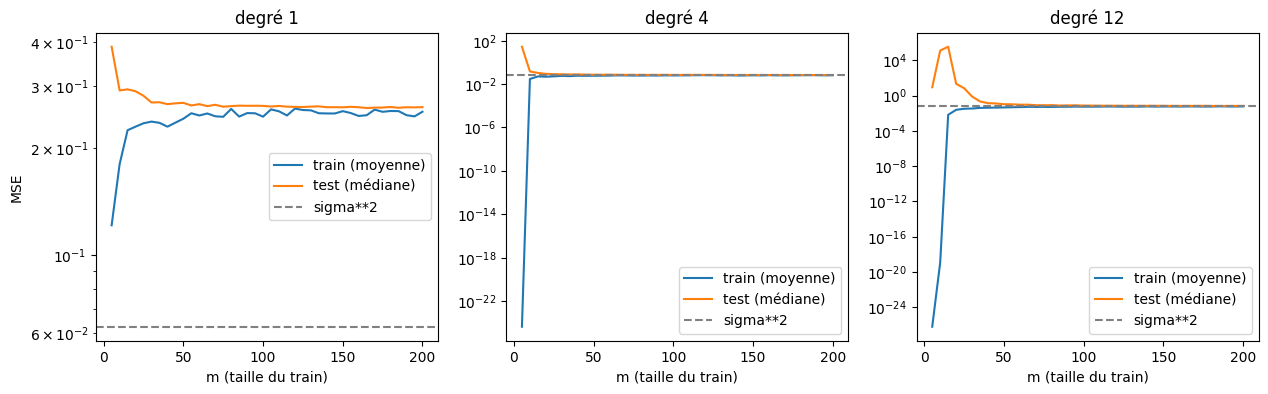

In [72]:
tailles = np.arange(5, 201, 5)          # m = 5, 10, ..., 200
rng_lc = np.random.default_rng(7)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, d in zip(axes, (1, 4, 12)):
    tr, te = courbe_apprentissage(d, tailles, 50, rng_lc)
    ax.plot(tailles, tr, label="train (moyenne)")
    ax.plot(tailles, te, label="test (médiane)")
    ax.axhline(SIGMA**2, color="gray", ls="--", label="sigma**2")
    ax.set_yscale("log")
    ax.set_title(f"degré {d}")
    ax.set_xlabel("m (taille du train)")
    ax.legend()
axes[0].set_ylabel("MSE")
plt.show()

### Questions — Partie 3

- **Q5.** Degré 1 : comment évoluent les deux courbes quand $m$ augmente ? Vers quoi convergent-elles ? Ajouter des données aide-t-il ? *(Test de maîtrise de B12-8.)*
- **Q6.** Degré 12 : même question. À partir de combien de points devient-il utilisable ?
- **Q7.** Degré 12 : observe l'erreur de test autour de $m \approx 13$. Que se passe-t-il, et pourquoi précisément là ? *(Lien avec B12-5 : double descente, $n \approx d$.)*

**Tes réponses :**

- Q5 :
- Q6 :
- Q7 : 

## Partie 4 (bonus) — Le lien avec les valeurs propres

Pour les degrés 5, 10 et 15, affiche le conditionnement `np.linalg.cond(X)` :
- **(a)** avec `features_poly` ($z \in [-1, 1]$) ;
- **(b)** avec les puissances de $x$ brut : `np.vander(x_train, deg + 1, increasing=True)`.

In [77]:
for d in (5, 10, 15):
    c_z = np.linalg.cond(features_poly(x_train, d))                       # (a) z dans [-1, 1]
    c_x = np.linalg.cond(np.vander(x_train, d + 1, increasing=True))      # (b) x brut dans [0, 1]
    print(f"degré {d:2d} | cond avec z : {c_z:.1e} | cond avec x brut : {c_x:.1e}")

degré  5 | cond avec z : 5.3e+01 | cond avec x brut : 5.2e+03
degré 10 | cond avec z : 5.3e+03 | cond avec x brut : 5.2e+07
degré 15 | cond avec z : 6.6e+05 | cond avec x brut : 6.3e+11


### Questions — Partie 4

- **Q8.** Lequel est le plus mal conditionné, et pourquoi ? *(Pense à $x^{14}$ et $x^{15}$ quand $x \in [0, 1]$ : ces deux colonnes se ressemblent-elles ?)*
- **Q9.** Quel rapport avec les deux sondes de pression du cours ?

**Tes réponses :**

- Q8 :
- Q9 : 